In [ ]:
#librerias
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Tareita 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

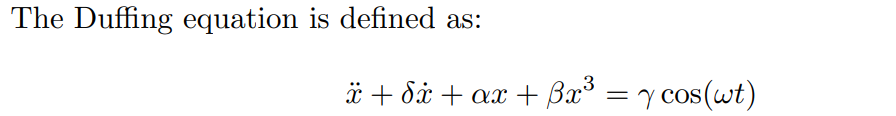

## Runge-Kutta de 4°

In [ ]:
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h/2 * np.array(k1))
    k3 = f(t + h/2, y + h/2 * np.array(k2))
    k4 = f(t + h, y + h * np.array(k3))
    return y + h/6 * (np.array(k1) + 2*np.array(k2) + 2*np.array(k3) + np.array(k4))

In [ ]:
def solve_ivp_rk4(f, t_span, y0, t_eval):
    t0, tf = t_span
    y = np.array(y0)
    sol_t = [t0]
    sol_y = [y]
    h = (tf - t0) / len(t_eval)

    for t in t_eval[1:]:
        y = rk4_step(f, sol_t[-1], sol_y[-1], h)
        sol_t.append(t)
        sol_y.append(y)

    return np.array(sol_t), np.array(sol_y).T

## Duffing

In [ ]:
# Params
delta = 0  # Amortiguamiento
alpha = 1   # Rigidez lineal
beta = 10
gamma = 0  # Amplitud de la fuerza externa
omega = 0  # Frecuencia de la fuerza externa

In [ ]:
def duffing(t, y):
    x, v = y
    dxdt = v
    dvdt = -delta * v - alpha * x - beta * x**3 + gamma * np.cos(omega * t)
    return [dxdt, dvdt]

In [ ]:
t_span = (0, 300)
t_eval = np.linspace(0, 3000, 10000)
y0 = [0.1, 0.1]

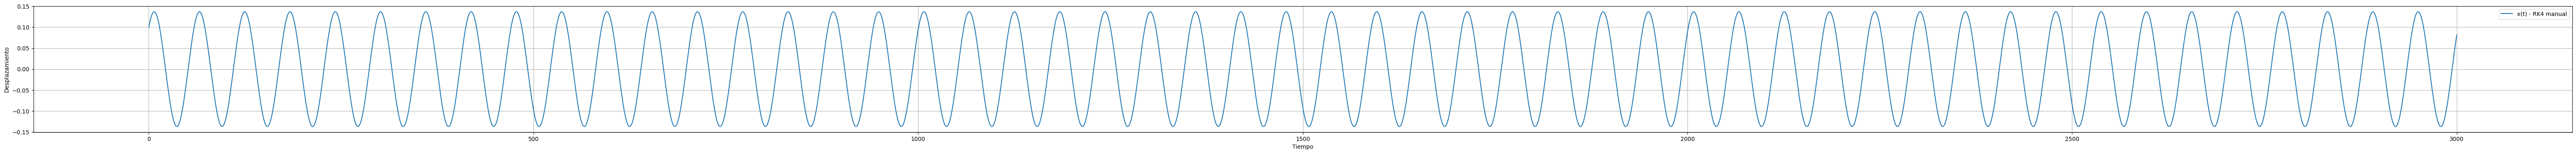

In [ ]:
t_rk4, y_rk4 = solve_ivp_rk4(duffing, t_span, y0, t_eval)
plt.figure(figsize=(80, 4))
plt.plot(t_rk4, y_rk4[0], label='x(t) - RK4 manual')
plt.xlabel('Tiempo')
plt.ylabel('Desplazamiento')
plt.legend()
plt.grid()
plt.show()

##Liapunov exponent

In [ ]:
def lyapunov_exp(system, y0, t_span, t_eval):
    epsilon = 1e-8  # Pequeña perturbación
    y1 = np.array(y0) + epsilon  # Estado perturbado

    t_rk4_1, sol_1 = solve_ivp_rk4(system, t_span, y0, t_eval)
    t_rk4_2, sol_2 = solve_ivp_rk4(system, t_span, y1, t_eval)

    d_0 = np.linalg.norm(np.array(y1) - np.array(y0)) + 1e-10  # Evitar división por cero
    d_t = np.linalg.norm(sol_2 - sol_1, axis=0) + 1e-10  # Evitar valores muy pequeños

    lyap_exp = np.mean(np.log(d_t / d_0)) / (t_eval[-1] - t_eval[0])
    return lyap_exp

In [ ]:
lyap = lyapunov_exp(duffing, y0, t_span, t_eval)
print(f"Exponente de Lyapunov estimado: {lyap}")

Exponente de Lyapunov estimado: 0.0008820723283942211


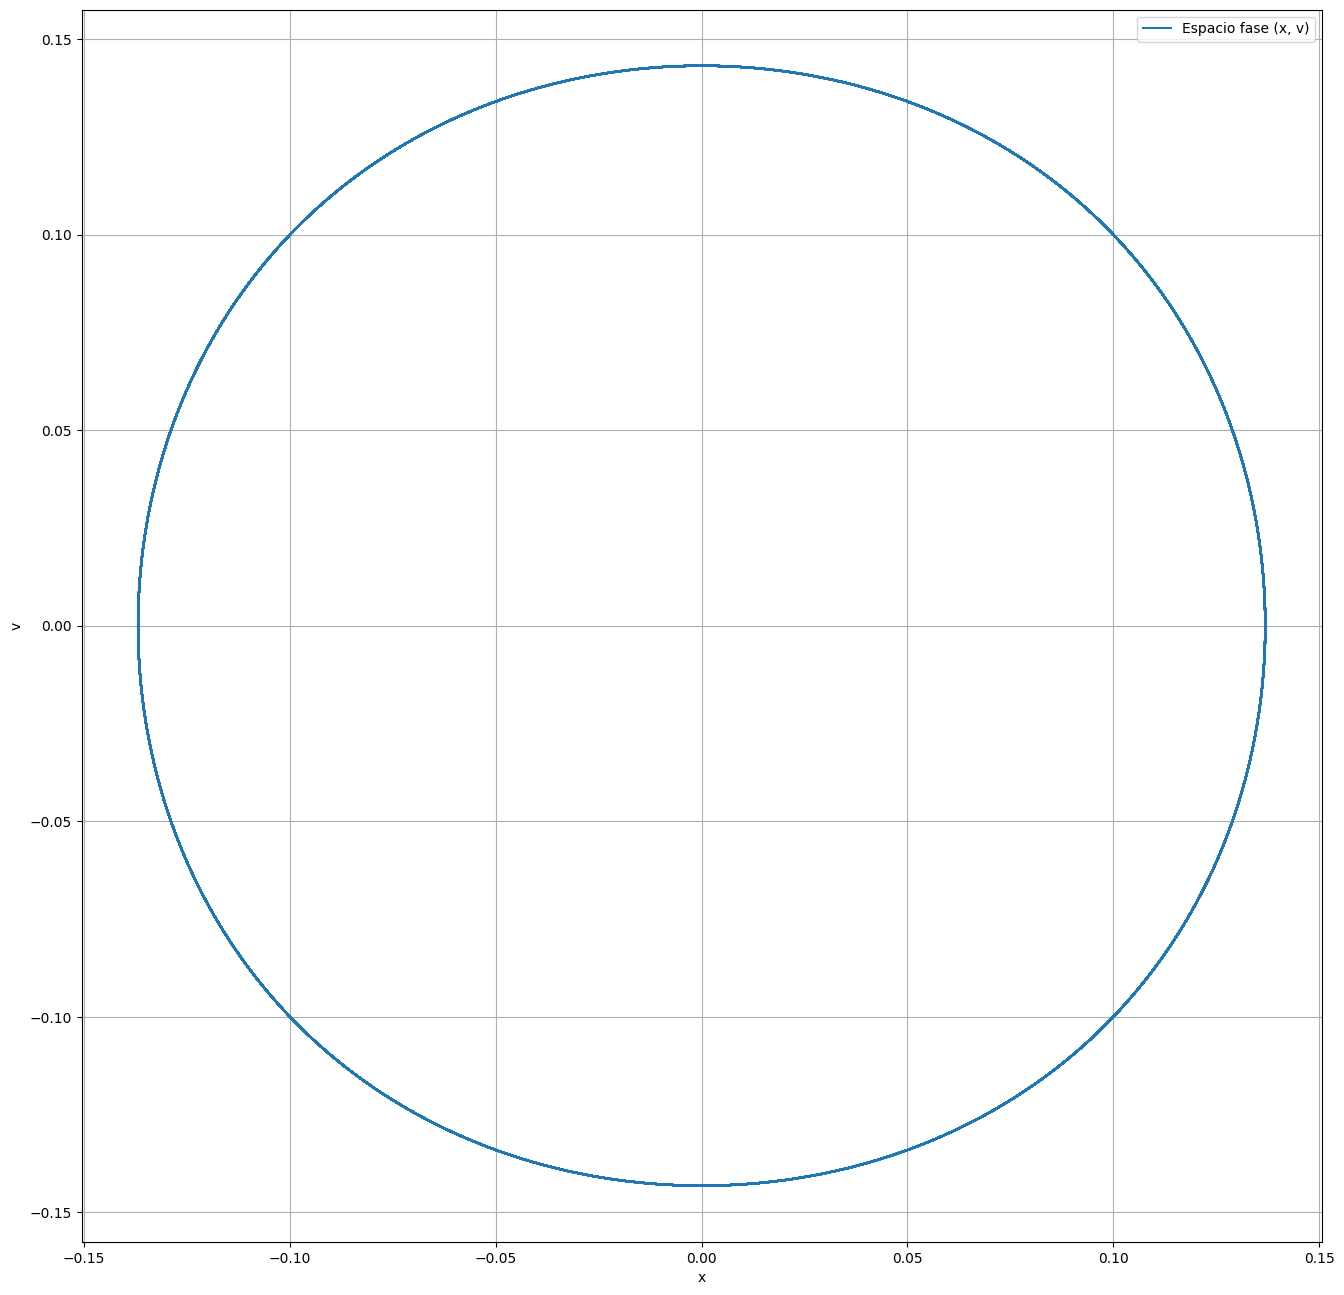

In [ ]:
plt.figure(figsize=(16, 16))
plt.plot(y_rk4[0], y_rk4[1], label='Espacio fase (x, v)')
plt.xlabel('x')
plt.ylabel('v')
plt.legend()
plt.grid()
plt.show()

# Tareita 2

## Explorar ejemplo del libro

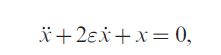

### Grafica segun libro

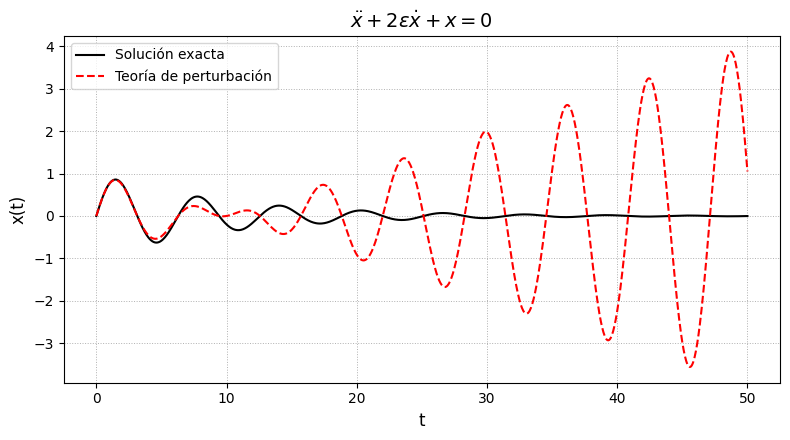

In [ ]:
epsilon = 0.1

# tiempo
t = np.linspace(0, 50, 1000)

# Solución exacta (del libro)
x_exact = np.exp(-epsilon * t) * np.sin(t)

# Aproximación por perturbación regular (del libro)
x_pert = np.sin(t) - epsilon * t * np.sin(t)

# Grafica
plt.figure(figsize=(8, 4.5))
plt.plot(t, x_exact, 'k-', label='Solución exacta', linewidth=1.5)
plt.plot(t, x_pert, 'r--', label='Teoría de perturbación', linewidth=1.5)

plt.xlabel("t", fontsize=12)
plt.ylabel("x(t)", fontsize=12)
plt.title(r"$\ddot{x} + 2\epsilon\dot{x} + x = 0$", fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.tight_layout()
plt.show()


### Grafico con ipv

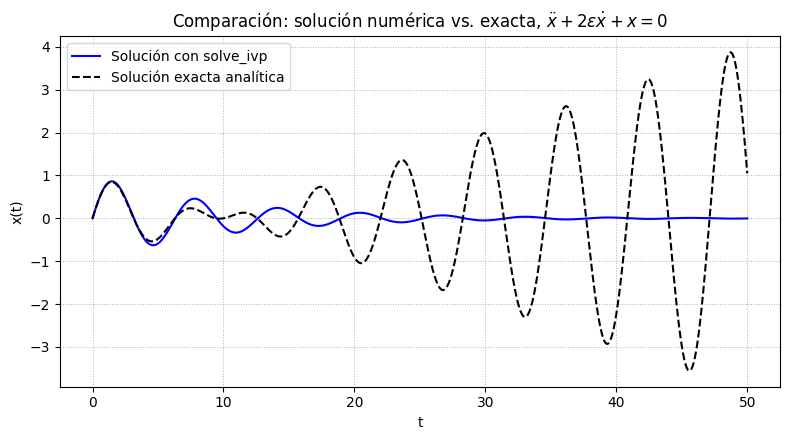

In [ ]:
epsilon = 0.1

# eq en sistema
def system(t, y):
    x1, x2 = y
    dx1dt = x2
    dx2dt = -2 * epsilon * x2 - x1
    return [dx1dt, dx2dt]

# condiciones iniciales
y0 = [0, 1]

t_eval = np.linspace(0, 50, 1000)

# sol exacta
sol = solve_ivp(system, [t_eval[0], t_eval[-1]], y0, t_eval=t_eval)

# Aproximación pert
x_pert = np.sin(t) - epsilon * t * np.sin(t)

# Grafica
plt.figure(figsize=(8, 4.5))
plt.plot(t_eval, sol.y[0], 'b-', label='Solución con solve_ivp', linewidth=1.5)
plt.plot(t_eval, x_pert, 'k--', label='Solución exacta analítica', linewidth=1.5)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(r"Comparación: solución numérica vs. exacta, $\ddot{x} + 2\epsilon \dot{x} + x = 0$")
plt.legend()
plt.grid(True, linestyle=':', linewidth=0.7)
plt.tight_layout()
plt.show()


## Duffing eq con pert

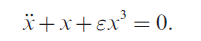

In [ ]:
epsilon = 0.001
a = 1.0  # amplitud inicial

t_eval = np.linspace(0, 20, 1000)

def duffing(t, y):
    x, dx = y
    ddx = -x - epsilon * x**3
    return [dx, ddx]

y0 = [a, 0]

# solu exacta
sol_exacta = solve_ivp(duffing, [t_eval[0], t_eval[-1]], y0, t_eval=t_eval)

# Solu pert
x0 = a * np.cos(t_eval)
x1 = (3 * a**3 / 8) * t_eval * np.sin(t_eval) + (a**3 / 32) * np.cos(3 * t_eval)
x_pert = x0 + epsilon * x1

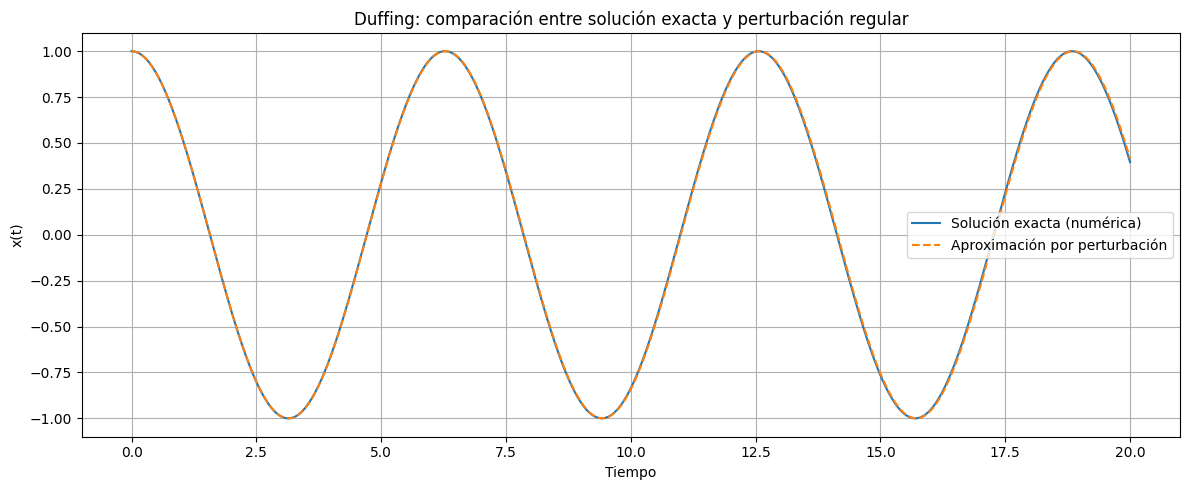

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(t_eval, sol_exacta.y[0], label="Solución exacta (numérica)")
plt.plot(t_eval, x_pert, '--', label="Aproximación por perturbación")
plt.xlabel("Tiempo")
plt.ylabel("x(t)")
plt.title("Duffing: comparación entre solución exacta y perturbación regular")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

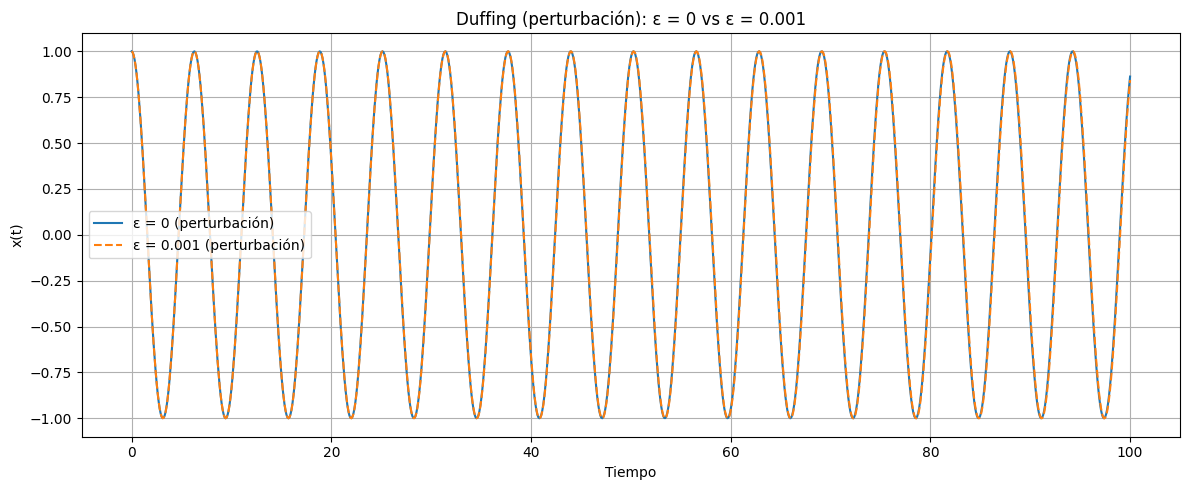

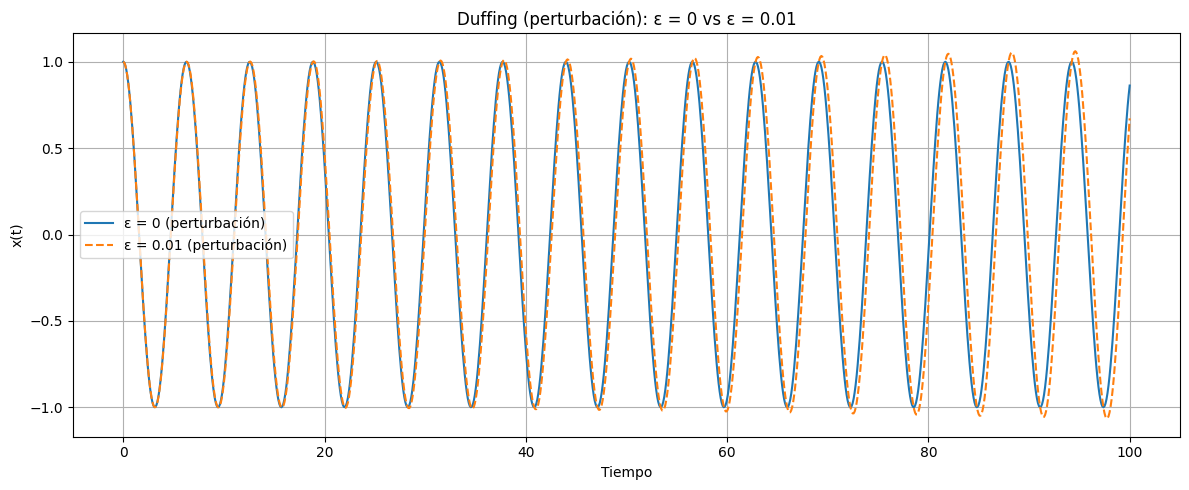

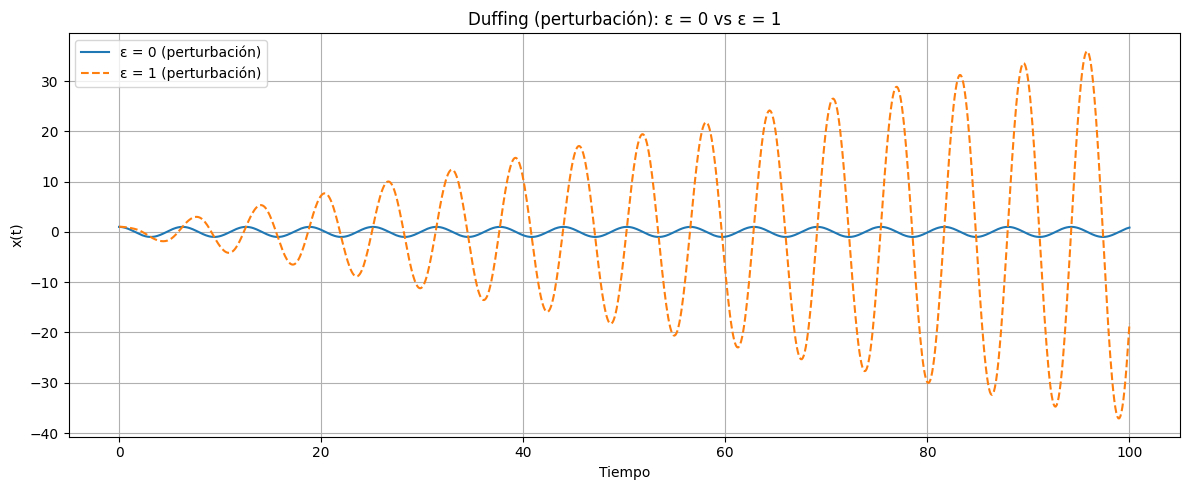

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

a = 1.0  # amplitud inicial
t_eval = np.linspace(0, 100, 1000)  # menos tiempo para que se vea mejor

# Solución perturbativa general
def x_pert(t, eps, a=1.0):
    x0 = a * np.cos(t)
    x1 = (3 * a**3 / 8) * t * np.sin(t) + (a**3 / 32) * np.cos(3 * t)
    return x0 + eps * x1

# Caso base (ε=0)
x_ref = x_pert(t_eval, 0, a)

# Otros valores de epsilon
epsilons = [0.001, 0.01, 1]

for eps in epsilons:
    x_eps = x_pert(t_eval, eps, a)

    plt.figure(figsize=(12, 5))
    # Línea sólida: referencia (ε = 0)
    plt.plot(t_eval, x_ref, label="ε = 0 (perturbación)", linestyle="-")
    # Línea cortada: caso actual
    plt.plot(t_eval, x_eps, label=f"ε = {eps} (perturbación)", linestyle="--")

    plt.xlabel("Tiempo")
    plt.ylabel("x(t)")
    plt.title(f"Duffing (perturbación): ε = 0 vs ε = {eps}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


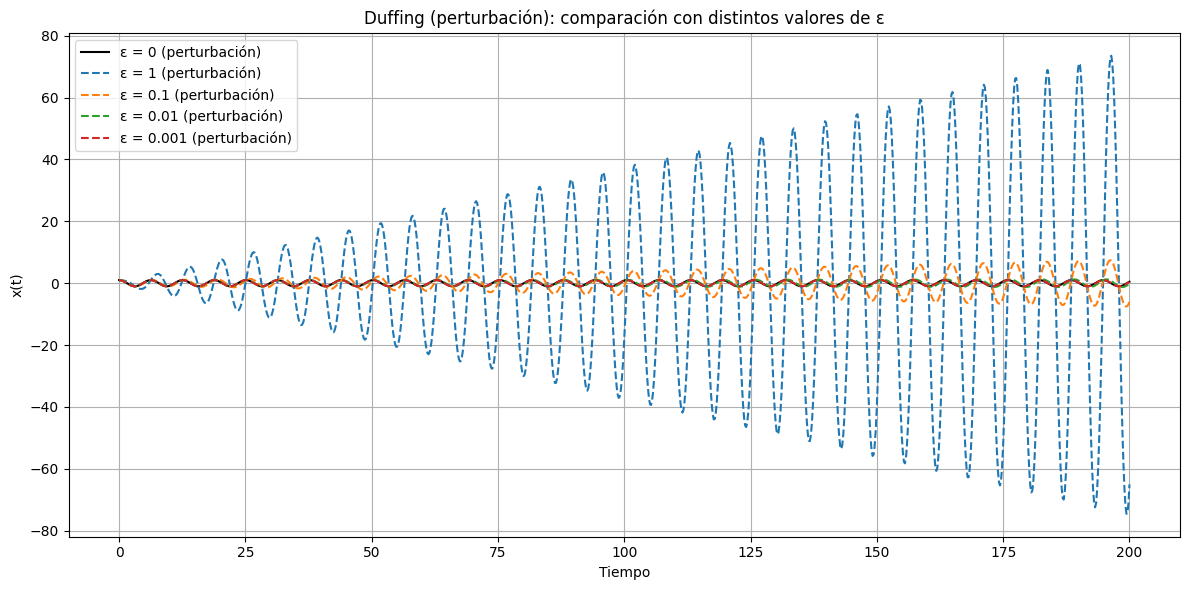

In [ ]:
t_eval = np.linspace(0, 200, 1000)
x_ref = x_pert(t_eval, 0, a)
plt.figure(figsize=(12, 6))
plt.plot(t_eval, x_ref, label="ε = 0 (perturbación)", linestyle="-", color="black")
epsilons=[1,0.1,0.01,0.001]
for eps in epsilons:
    x_eps = x_pert(t_eval, eps, a)
    plt.plot(t_eval, x_eps, label=f"ε = {eps} (perturbación)", linestyle="--")

plt.xlabel("Tiempo")
plt.ylabel("x(t)")
plt.title("Duffing (perturbación): comparación con distintos valores de ε")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
